### 什么是输出解析器(OutputParses)？
---
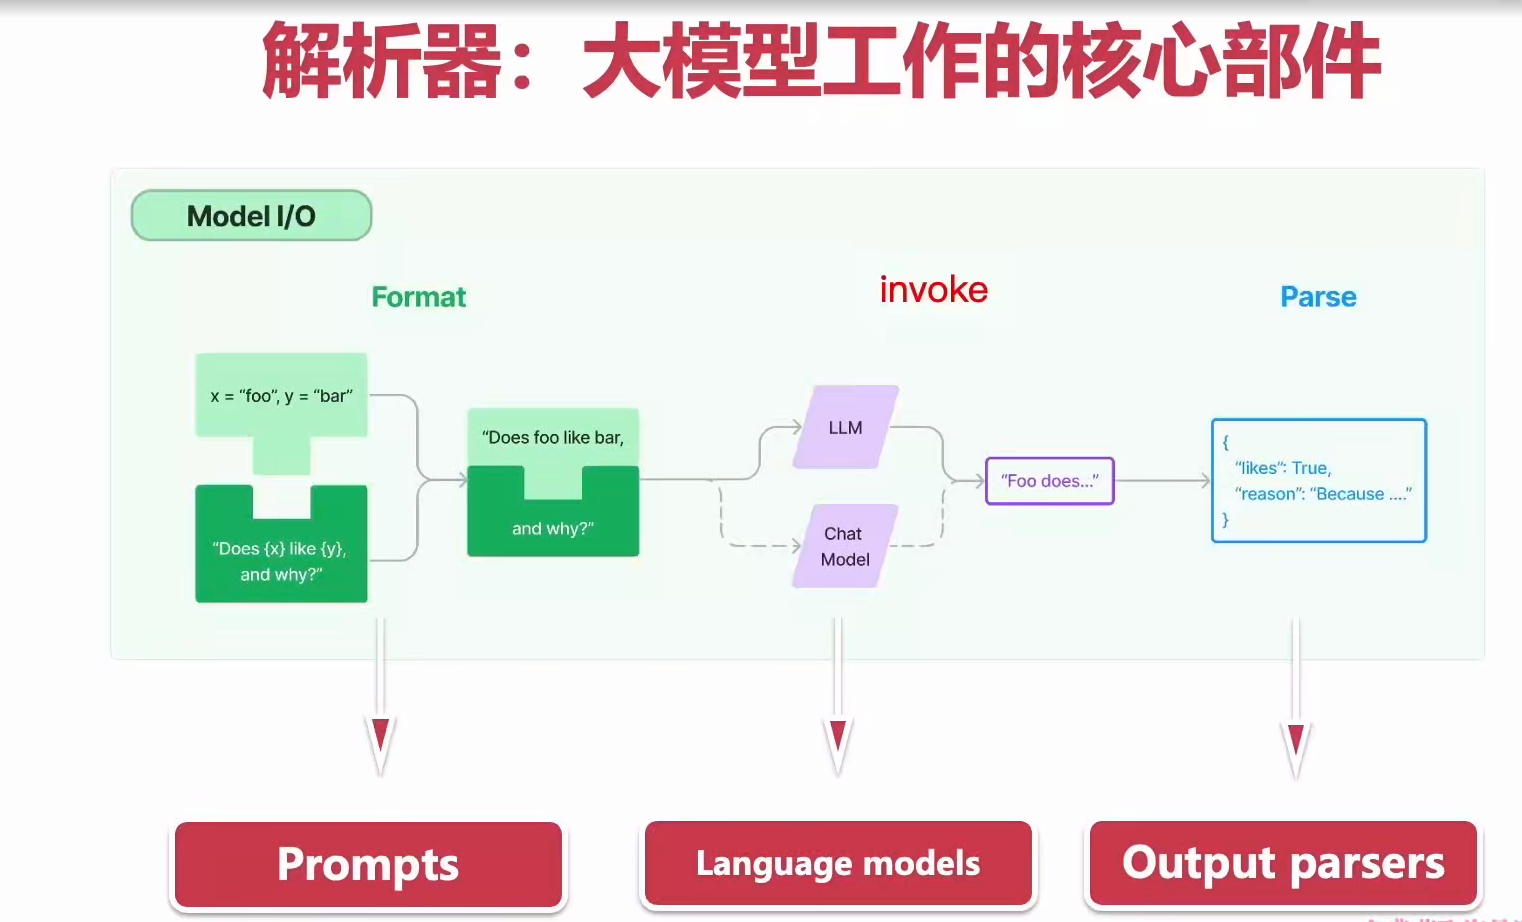
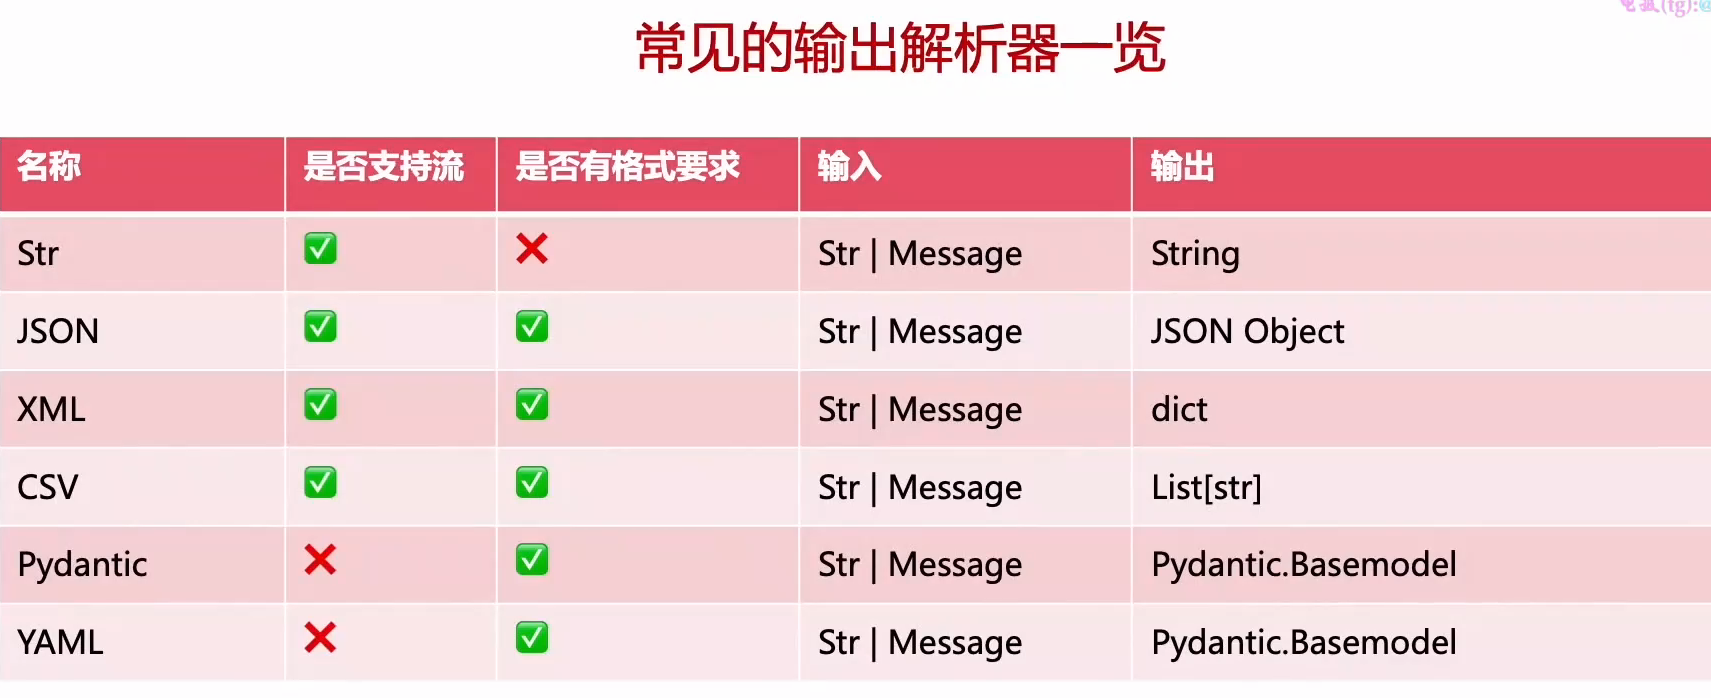

* 不同的输出器在输出上都会不通
* 注意有一些输出器是不支持流式输出的
* 当解析器有格式要求的时候，需要在提示词模板格式化的时候，将格式要求实例化进去
* 下游承接输出时，要注意数据格式兼容问题

### Langchain支持的主要输出格式
---
1. 文本  
    * 非标原生方式（不推荐）
    * StrOutputParser (简化提取过程)
2. Pydantic - PydanticOutputParser
3. JSON - JsonOutputParser
4. XML - XMLOutputParser

In [ ]:
from langchain_deepseek import ChatDeepSeek

import os
from dotenv import load_dotenv  

load_dotenv()  # Load environment variables from .env file

model = ChatDeepSeek(
    model="deepseek-ai/DeepSeek-V4.1-Flash",  # 模型名称          
    api_key=os.getenv("api_key"),  # 在环境变量中设置的API Key
    base_url=os.getenv("base_url"), # 在环境变量中设置的API请求地址
    temperature=0,
)

response = model.invoke("请帮我写一段Python代码，使用LangChain框架实现一个简单的聊天机器人。")

# deepseek 使用.content作为输出文本的字段
# 虽然很多LLM使用同样的字段，但这并不是行业标准
# 所以要谨慎使用
print("模型响应:", response)

模型响应: content='# LangChain 简单聊天机器人\n\n下面是一个可直接运行的示例，包含**对话记忆**（多轮上下文）、**命令行交互**，使用的是当前推荐的 LangChain 0.3 写法（`ChatPromptTemplate` + `RunnableWithMessageHistory`）。\n\n## 1. 环境准备\n\n```bash\npip install -U langchain langchain-openai python-dotenv\nexport OPENAI_API_KEY="sk-..."   # 或写进 .env 文件\n```\n\n## 2. 完整代码\n\n```python\n# chatbot.py\n"""\n一个使用 LangChain 实现的简单聊天机器人（带多轮对话记忆）\n"""\n\nimport os\nfrom dotenv import load_dotenv\n\nfrom langchain_openai import ChatOpenAI\nfrom langchain_core.prompts import ChatPromptTemplate, MessagesPlaceholder\nfrom langchain_core.chat_history import InMemoryChatMessageHistory\nfrom langchain_core.runnables.history import RunnableWithMessageHistory\n\nload_dotenv()\n\n# ---------- 1. 初始化大模型 ----------\nllm = ChatOpenAI(\n    model="gpt-4o-mini",\n    temperature=0.7,\n    # api_key 会自动从环境变量 OPENAI_API_KEY 读取\n)\n\n# ---------- 2. 提示模板 ----------\nprompt = ChatPromptTemplate.from_messages([\n    ("system", "你是一个乐于助人的中文助手，回答要简洁清晰。"),\n    MessagesPlaceholde

#### 1.文本
---

In [2]:
# StrOutputParser 可以大幅优化从LangChain中提取文本
# 假设有一个被绑定了工具的LLM
from langchain_openai import ChatOpenAI
import os
from dotenv import load_dotenv

load_dotenv()  # Load environment variables from .env file

model = ChatOpenAI(
    model="Qwen/Qwen3.8-27B",  # 模型名称          
    api_key=os.getenv("api_key"),  # 在环境变量中设置的API Key
    base_url=os.getenv("base_url"), # 在环境变量中设置的API请求地址
    temperature=0,
)

# 定义一个假的实时天气预报工具
# 传入地名返回实时天气
from langchain_core.tools import tool
@tool
def get_weather(location: str) -> str:
    """根据location地名返回当地的实时天气预报"""
    return f"{location}天气晴朗22度"

# 绑定工具
model_with_tool = model.bind_tools([get_weather])

# 引入StrOutputParser
from langchain_core.output_parsers import StrOutputParser

# 1. 让模型输出指令
response_msg = model_with_tool.invoke("北京市当前的天气如何？")

# 2. 检查模型是否决定调用工具
if response_msg.tool_calls:
    tool_call = response_msg.tool_calls[0]
    
    # 3. 手动执行工具 (员工干活)
    tool_result = get_weather.invoke(tool_call["args"])
    print(f"🔧 工具执行结果: {tool_result}")
    
    # 4. 把结果作为 ToolMessage 传回给模型，让它生成最终回答
    from langchain_core.messages import ToolMessage, HumanMessage
    final_msg = model.invoke([
        HumanMessage(content="北京市当前的天气如何？"),
        response_msg, # 包含 tool_calls 的消息
        ToolMessage(content=tool_result, tool_call_id=tool_call["id"]) # 工具结果
    ])

    print(f"💬 模型最终回答: {final_msg.content}")

    # 5. 现在模型已经口头回答了，再用 StrOutputParser 提取就有效了
    parser = StrOutputParser()
    final_answer = parser.invoke(final_msg)
    print(f"✅ 最终回答: {final_answer}")

🔧 工具执行结果: 北京市天气晴朗22度
💬 模型最终回答: 

北京市当前天气晴朗，气温为22度。
✅ 最终回答: 

北京市当前天气晴朗，气温为22度。


#### 2.Pydantic - PydanticOutputParser
---

In [ ]:
from langchain_core.output_parsers import PydanticOutputParser
from langchain_core.prompts import PromptTemplate
from pydantic import BaseModel, Field, model_validator
from langchain_openai import ChatOpenAI  # 建议用 langchain_openai，兼容性更好
import os
from dotenv import load_dotenv

load_dotenv()

# 1. 初始化模型
model = ChatOpenAI(
    model="Qwen/Qwen3-8B",  # 请确认你实际使用的模型名称
    api_key=os.getenv("api_key"),
    base_url=os.getenv("base_url"),
    temperature=0,
)

# 2. 定义 Pydantic 数据模型
class Joke(BaseModel):
    setup: str = Field(description="笑话中的铺垫问题，必须以？结尾")
    punchline: str = Field(description="笑话中回答铺垫问题的部分，通常是抖包袱")

    @model_validator(mode="before")
    @classmethod
    def question_ends_with_question_mark(cls, values: dict) -> dict:
        setup = values.get("setup")
        if setup and not setup.endswith("？"):
            raise ValueError("Badly formed joke: setup must end with a question mark.")
        return values

# 3. 实例化解析器
parser = PydanticOutputParser(pydantic_object=Joke)

# 4. 定义提示词模板
# ✅ 在 template 中加入 {query}，让用户输入有地方放
prompt = PromptTemplate(
    template="回答用户的查询。\n{query}\n{format_instructions}",  # <--- 加入了 {query}
    input_variables=["query"],
    partial_variables={"format_instructions": parser.get_format_instructions()}
)

print("PydanticOutParser 格式化指令:", parser.get_format_instructions())

# 5. ✅ 使用正确的 LCEL 链顺序：prompt -> model -> parser
chain = prompt | model | parser

# 6. 调用链
try:
    output = chain.invoke({"query": "给我讲一个笑话"})
    print(output)
    print("✅ 成功解析为 Joke 对象：")
    print(f"铺垫: {output.setup}")
    print(f"笑点: {output.punchline}")
except Exception as e:
    print(f"❌ 调用失败: {e}")

PydanticOutParser 格式化指令: The output should be formatted as a JSON instance that conforms to the JSON schema below.

As an example, for the schema {"properties": {"foo": {"title": "Foo", "description": "a list of strings", "type": "array", "items": {"type": "string"}}}, "required": ["foo"]}
the object {"foo": ["bar", "baz"]} is a well-formatted instance of the schema. The object {"properties": {"foo": ["bar", "baz"]}} is not well-formatted.

Here is the output schema:
```
{"properties": {"setup": {"description": "笑话中的铺垫问题，必须以？结尾", "title": "Setup", "type": "string"}, "punchline": {"description": "笑话中回答铺垫问题的部分，通常是抖包袱", "title": "Punchline", "type": "string"}}, "required": ["setup", "punchline"]}
```
setup='为什么数学书总是很忧郁？' punchline='因为它有太多的问题！'
✅ 成功解析为 Joke 对象：
铺垫: 为什么数学书总是很忧郁？
笑点: 因为它有太多的问题！


#### 3. JSON - JsonOutputParser
---

In [20]:
from langchain_core.output_parsers import JsonOutputParser
from langchain_core.prompts import PromptTemplate
from pydantic import BaseModel, Field, model_validator
from langchain_openai import ChatOpenAI  # 建议用 langchain_openai，兼容性更好
import os
from dotenv import load_dotenv

load_dotenv()

# 1. 初始化模型
model = ChatOpenAI(
    model="Qwen/Qwen3-8B",  # 请确认你实际使用的模型名称
    api_key=os.getenv("api_key"),
    base_url=os.getenv("base_url"),
    temperature=0,
)

# 2. 定义 Pydantic 数据模型
class Joke(BaseModel):
    setup: str = Field(description="笑话中的铺垫问题，必须以？结尾")
    punchline: str = Field(description="笑话中回答铺垫问题的部分，通常是抖包袱")

# 3. 实例化解析器
parser = JsonOutputParser(pydantic_object=Joke)

# 4. 定义提示词模板
# ✅ 在 template 中加入 {query}，让用户输入有地方放
prompt = PromptTemplate(
    template="回答用户的查询。\n{query}\n{format_instructions}",  # <--- 加入了 {query}
    input_variables=["query"],
    partial_variables={"format_instructions": parser.get_format_instructions()}
)

print("JsonOutputParser 格式化指令:", parser.get_format_instructions())

# 5. ✅ 使用正确的 LCEL 链顺序：prompt -> model -> parser
chain = prompt | model | parser

# 6. 调用链
try:
    output = chain.invoke({"query": "给我讲一个笑话"})
    print(output)
    print("✅ 成功解析为字典 (dict)：")
    print(type(output))  # 这里会显示 <class 'dict'>
    
    # ✅ 关键修改：使用字典的键值访问方式
    print(f"铺垫: {output['setup']}")
    print(f"笑点: {output['punchline']}")
except Exception as e:
    print(f"❌ 调用失败: {e}")

JsonOutputParser 格式化指令: STRICT OUTPUT FORMAT:
- Return only the JSON value that conforms to the schema. Do not include any additional text, explanations, headings, or separators.
- Do not wrap the JSON in Markdown or code fences (no ``` or ```json).
- Do not prepend or append any text (e.g., do not write "Here is the JSON:").
- The response must be a single top-level JSON value exactly as required by the schema (object/array/etc.), with no trailing commas or comments.

The output should be formatted as a JSON instance that conforms to the JSON schema below.

As an example, for the schema {"properties": {"foo": {"title": "Foo", "description": "a list of strings", "type": "array", "items": {"type": "string"}}}, "required": ["foo"]} the object {"foo": ["bar", "baz"]} is a well-formatted instance of the schema. The object {"properties": {"foo": ["bar", "baz"]}} is not well-formatted.

Here is the output schema (shown in a code block for readability only — do not include any backticks or Ma

In [ ]:
from langchain_core.output_parsers import JsonOutputParser
from langchain_core.prompts import PromptTemplate
from pydantic import BaseModel, Field
from langchain_openai import ChatOpenAI  # 建议用 langchain_openai，兼容性更好
import os
from dotenv import load_dotenv

load_dotenv()

# 1. 初始化模型
model = ChatOpenAI(
    model="Qwen/Qwen3-8B",  # 请确认你实际使用的模型名称
    api_key=os.getenv("api_key"),
    base_url=os.getenv("base_url"),
    temperature=0,
)

# 2. 定义 Pydantic 数据模型
class Joke(BaseModel):
    setup: str = Field(description="笑话中的铺垫问题，必须以？结尾")
    punchline: str = Field(description="笑话中回答铺垫问题的部分，通常是抖包袱")

# 3. 实例化解析器
parser = JsonOutputParser(pydantic_object=Joke)

# 4. 定义提示词模板
# ✅ 在 template 中加入 {query}，让用户输入有地方放
prompt = PromptTemplate(
    template="回答用户的查询。\n{query}\n{format_instructions}",  # <--- 加入了 {query}
    input_variables=["query"],
    partial_variables={"format_instructions": parser.get_format_instructions()}
)

# print("JsonOutputParser 格式化指令:", parser.get_format_instructions())

# 5. ✅ 使用正确的 LCEL 链顺序：prompt -> model -> parser
chain = prompt | model | parser

# 6. 调用链：使用 stream() 实现流式输出
try:
    print("🔄 开始流式生成...\n")
    
    # ✅ 关键修改：使用 .stream() 而不是 .invoke()
    for chunk in chain.stream({"query": "给我讲一个笑话"}):
        # chunk 是逐步解析出来的字典片段
        print(chunk) 
        
    print("\n\n✅ 流式输出完成！")
    
except Exception as e:
    print(f"❌ 调用失败: {e}")

🔄 开始流式生成...

{}
{'setup': ''}
{'setup': '为什么'}
{'setup': '为什么电脑'}
{'setup': '为什么电脑会'}
{'setup': '为什么电脑会感冒'}
{'setup': '为什么电脑会感冒？'}
{'setup': '为什么电脑会感冒？', 'punchline': ''}
{'setup': '为什么电脑会感冒？', 'punchline': '因为它'}
{'setup': '为什么电脑会感冒？', 'punchline': '因为它打开了'}
{'setup': '为什么电脑会感冒？', 'punchline': '因为它打开了太多'}
{'setup': '为什么电脑会感冒？', 'punchline': '因为它打开了太多窗口'}
{'setup': '为什么电脑会感冒？', 'punchline': '因为它打开了太多窗口。'}


✅ 流式输出完成！


#### 4. XML - XMLOutputParser
---

In [34]:
from langchain_core.output_parsers import XMLOutputParser
from langchain_core.prompts import PromptTemplate
from langchain_openai import ChatOpenAI  # 建议用 langchain_openai，兼容性更好
import os
from dotenv import load_dotenv

load_dotenv()

# 1. 初始化模型
model = ChatOpenAI(
    model="Qwen/Qwen3-8B",  # 请确认你实际使用的模型名称
    api_key=os.getenv("api_key"),
    base_url=os.getenv("base_url"),
    temperature=0,
)

actor_query = "Generate the shortened filmography for Tom Hanks."

parser = XMLOutputParser(tags=["movies", "actor", "film", "name", "genre"])
# print("XMLOutputParser 格式化指令:\n", parser.get_format_instructions())

prompt = PromptTemplate(
    template="请以XML格式回答用户的查询。\n{query}\n{format_instructions}",  # <--- 加入了 {query}
    input_variables=["query"],
    partial_variables={"format_instructions": parser.get_format_instructions()}
)

chain = prompt | model #| parser

output = chain.invoke({"query": actor_query})
print("模型输出的XML内容:\n", output)


模型输出的XML内容:
 content='\n\n<?xml version="1.0" encoding="UTF-8"?>\n<movies>\n  <actor>\n    <film>\n      <name>Forrest Gump</name>\n      <genre>Drama</genre>\n    </film>\n    <film>\n      <name>The Green Mile</name>\n      <genre>Fantasy</genre>\n    </film>\n    <film>\n      <name>Saving Private Ryan</name>\n      <genre>War</genre>\n    </film>\n    <film>\n      <name>The Da Vinci Code</name>\n      <genre>Thriller</genre>\n    </film>\n    <film>\n      <name>Cloud Atlas</name>\n      <genre>Drama</genre>\n    </film>\n  </actor>\n</movies>' additional_kwargs={'refusal': None} response_metadata={'token_usage': {'completion_tokens': 1073, 'prompt_tokens': 190, 'total_tokens': 1263, 'completion_tokens_details': {'accepted_prediction_tokens': None, 'audio_tokens': None, 'reasoning_tokens': 914, 'rejected_prediction_tokens': None}, 'prompt_tokens_details': {'audio_tokens': None, 'cache_write_tokens': None, 'cached_tokens': 0}, 'prompt_cache_hit_tokens': 0, 'prompt_cache_miss_tokens